# Benchmark on the IBM AML datasets

Reproduces the comparison asked for in the project specification: **structural motifs vs.
tabular baselines vs. GCN / GraphSAGE / GAT (supervised) vs. a graph auto-encoder
(unsupervised)** on a temporal split, with several seeds, standard deviations and confidence
intervals, plus the exploratory data analysis and the **per-motif recall** that the
`*_Patterns.txt` files make possible.

**Data.** Download `HI-Small_Trans.csv` / `LI-Small_Trans.csv` and the matching
`*_Patterns.txt` from the [IBM Transactions for AML](https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml)
Kaggle page (a Kaggle account is required; `amlgm download ibm --out data` does it with a Kaggle
API token) and point `AML_DATA` to the CSV, e.g. in Colab after mounting Drive:

```python
import os; os.environ["AML_DATA"] = "/content/drive/MyDrive/HI-Small_Trans.csv"
```

When `AML_DATA` is not set this notebook falls back to the **synthetic generator** so that it
always runs. Numbers obtained that way only validate the pipeline — **never quote them as IBM
results**.

In [1]:
%pip install -q "aml-graphminer[viz]"
# GPU runtime + GNNs:  %pip install -q "aml-graphminer[gnn]"   (PyTorch Geometric wheels depend on the torch version)

In [2]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import aml_graphminer as aml
from aml_graphminer.eda import eda_figures, eda_summary
from aml_graphminer.evaluation import bootstrap_ci, compute_metrics, run_benchmark
from aml_graphminer.ingestion import load_dataset
from aml_graphminer.utils import has_module

warnings.filterwarnings("ignore")
pd.set_option("display.width", 130)

## Configuration

In [3]:
DATA = os.environ.get("AML_DATA", "")
SEEDS = (0, 1, 2)
GNN_AVAILABLE = has_module("torch") and has_module("torch_geometric")
MODELS = ["patterns", "logreg", "rf", "hgb"] + (
    ["gcn", "sage", "gat", "gae"] if GNN_AVAILABLE else []
)
print(
    "models:",
    MODELS,
    "| GNNs:",
    "enabled" if GNN_AVAILABLE else "skipped (install the `gnn` extra)",
)

models: ['patterns', 'logreg', 'rf', 'hgb', 'gcn', 'sage', 'gat', 'gae'] | GNNs: enabled


## Load

In [4]:
if DATA and Path(DATA).exists():
    # load_dataset also attaches the motif names of the sibling *_Patterns.txt (per-motif recall)
    df = load_dataset(DATA, schema="ibm")
    DATASET = Path(DATA).stem
    SYNTHETIC = False
else:
    df = aml.generate_transactions(
        n_accounts=1500, n_background=15000, days=10, illicit_ratio=0.012, seed=11
    )
    DATASET = "synthetic-demo"
    SYNTHETIC = True
print(f"{DATASET}: {len(df):,} transactions, laundering share {df['label'].mean():.3%}")
if SYNTHETIC:
    print("SYNTHETIC STAND-IN — set AML_DATA to benchmark the real files.")

synthetic-demo: 15,269 transactions, laundering share 1.166%
SYNTHETIC STAND-IN — set AML_DATA to benchmark the real files.


## Exploratory data analysis

Milestone J1 of the project specification ("dataset loaded, EDA produced"). `eda_summary`
returns JSON-ready statistics and `eda_figures` the matching plots; `amlgm eda <file> --out
eda/` writes both plus a Markdown report.

In [5]:
eda = eda_summary(df)
pd.DataFrame(
    {
        "transactions": [eda["transactions"]],
        "accounts": [eda["accounts"]],
        "laundering": [eda["illicit"]],
        "laundering share": [f"{eda['illicit_ratio']:.3%}"],
        "max in/out degree": [f"{eda['degree']['max_in']} / {eda['degree']['max_out']}"],
        "reciprocal pairs": [f"{eda['structure']['reciprocal_pair_share']:.2%}"],
    }
)

,transactions,accounts,laundering,laundering share,max in/out degree,reciprocal pairs
0,15269,1626,178,1.166%,202 / 457,5.52%


In [6]:
pd.DataFrame(eda["payment_formats"]).set_index("name").round(4)

,transactions,illicit_rate
name,,
Credit Card,4466,0.0000
ACH,3377,0.0050
Cash,1917,0.0292
Cheque,1818,0.0209
Wire,1544,0.0350
Reinvestment,1536,0.0000
Bitcoin,611,0.0213


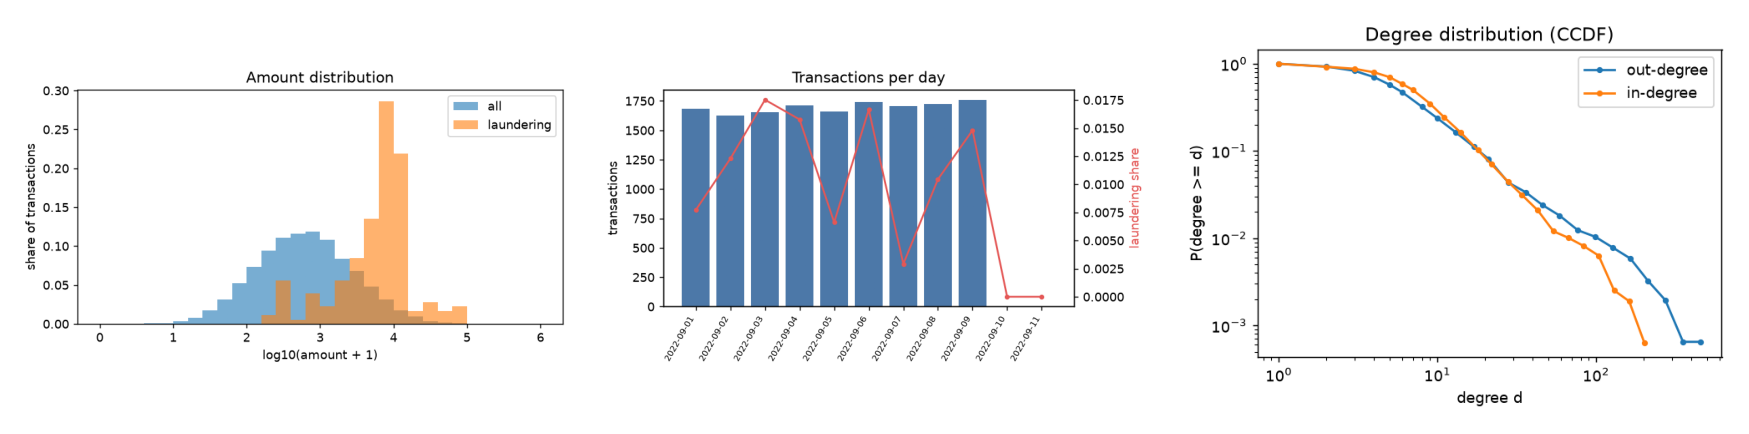

In [7]:
import tempfile

import matplotlib.image as mpimg

with tempfile.TemporaryDirectory() as tmp:
    figures = {p.stem: p for p in eda_figures(df, tmp, eda)}
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
    for ax, name in zip(axes, ("amounts", "daily", "degrees")):
        ax.imshow(mpimg.imread(figures[name]))
        ax.set_axis_off()
    plt.tight_layout()

## Run

`run_benchmark` splits in time (60/20/20), fits the feature pipeline on the training part,
selects every decision threshold on the **validation** split and reports test metrics.
Deterministic models (the motif scanner) run once; stochastic ones run once per seed.

In [8]:
report = run_benchmark(df, models=MODELS, seeds=SEEDS, dataset=DATASET)
report.config["split_sizes"], report.config["illicit_in_split"]

({'train': 9161, 'val': 3054, 'test': 3054}, {'train': 106, 'val': 29, 'test': 43})

In [9]:
summary = report.summary(metrics=("pr_auc", "f1", "precision", "recall", "recall_at_k"))
summary.round(4)

pr_auc              f1         precision          recall         recall_at_k        
                           mean     std    mean     std      mean     std    mean     std        mean     std
dataset        model                                                                                         
synthetic-demo gae       0.0595  0.0087  0.0783  0.0828    0.1066  0.1076  0.0620  0.0671      0.1473  0.0134
               gat       0.7342  0.0283  0.7785  0.0089    0.9375  0.0541  0.6667  0.0134      0.7054  0.0355
               gcn       0.7628  0.0388  0.7834  0.0131    0.8290  0.0264  0.7442  0.0403      0.7442  0.0403
               hgb       0.4218  0.0000  0.3929  0.0000    0.8462  0.0000  0.2558  0.0000      0.3953  0.0000
               logreg    0.6018  0.0000  0.5472  0.0000    0.4603  0.0000  0.6744  0.0000      0.5581  0.0000
               patterns  0.3222     NaN  0.1852     NaN    0.4545     NaN  0.1163     NaN      0.3256     NaN
               rf        0.4990  0.0337  0.5445  0.0312    0.8839  0.0464  0.3953  0.0403      0.4419  0.0000
               sage      0.5600  0.2918  0.5120  0.3418    0.6370  0.1404  0.4961  0.3709      0.5581  0.2641

`recall_at_k` is the metric of the original notebooks (k = number of positives, i.e.
R-precision). PR-AUC is the headline metric on such imbalanced data.

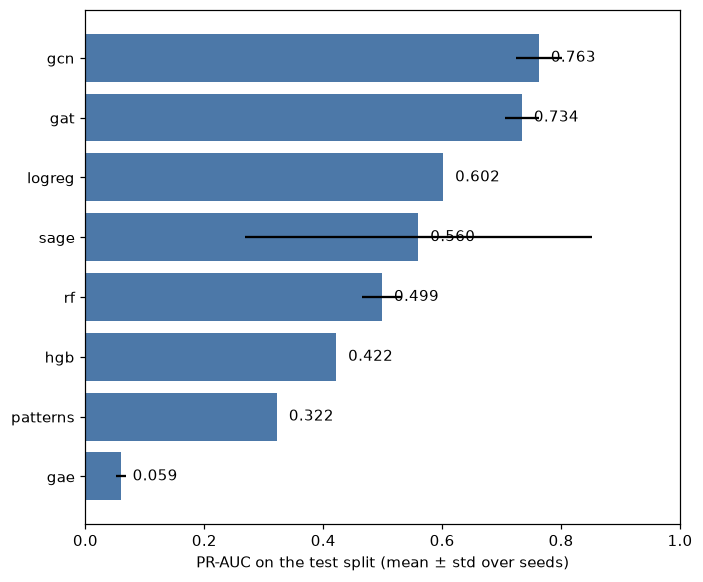

In [10]:
results = report.results
order = summary["pr_auc"]["mean"].sort_values().index.get_level_values("model")
mean = results.groupby("model")["pr_auc"].mean().reindex(order)
std = results.groupby("model")["pr_auc"].std().reindex(order).fillna(0)
fig, ax = plt.subplots(figsize=(6.5, 0.55 * len(mean) + 1))
ax.barh(mean.index, mean.values, xerr=std.values, color="#4C78A8")
ax.set(xlabel="PR-AUC on the test split (mean ± std over seeds)", xlim=(0, 1))
for y_pos, value in enumerate(mean.values):
    ax.text(min(value + 0.02, 0.9), y_pos, f"{value:.3f}", va="center")
plt.tight_layout()

## Confidence interval (bootstrap over test transactions)

In [11]:
masks = aml.temporal_split(df)
y_test = df.loc[masks["test"], "label"].to_numpy()
features = report.fitted["pipeline"].transform_splits(df, masks)
rows = []
for kind in ("logreg", "rf", "hgb"):
    if kind in report.fitted:
        p = report.fitted[kind].predict_proba(features["test"].tabular(masks["test"], True))
        lo, hi = bootstrap_ci(y_test, p, n_boot=200)
        rows.append(
            {
                "model": kind,
                "pr_auc": compute_metrics(y_test, p)["pr_auc"],
                "ci95_low": lo,
                "ci95_high": hi,
            }
        )
pd.DataFrame(rows).round(4)

,model,pr_auc,ci95_low,ci95_high
0,logreg,0.6018,0.4665,0.7364
1,rf,0.4626,0.3347,0.6128
2,hgb,0.4218,0.3059,0.5650


The interval comes from resampling the test transactions of the **last fitted seed**; seed
variance is already in the table above. For the thesis, report both.

## Per-motif recall

How many transactions of each laundering pattern does the (training-free) motif scanner
recover? `recall_same` counts alerts of the matching detector only; `recall_any` counts any
alert. With the real IBM files the `pattern` column comes from `*_Patterns.txt`.

In [12]:
report.per_pattern.round(
    3
) if report.per_pattern is not None else "no pattern information in this dataset"

,pattern,n_tx,recall_any,recall_same
0,cycle,5,1.000,1.000
1,fan_in,17,0.529,0.529
2,fan_out,21,0.571,0.571


## Save everything

In [13]:
out = report.save(Path("benchmark_results") / DATASET)
sorted(p.name for p in out.iterdir())

['config.json', 'per_pattern_recall.csv', 'results.csv', 'summary.csv', 'summary.md']

`results.csv` (one row per model × seed), `summary.csv`/`summary.md`, `config.json` (full
configuration of the run) and `per_pattern_recall.csv` are all that is needed to regenerate
the tables of the report. The command-line equivalent is:

```bash
amlgm eda HI-Small_Trans.csv --out results/hi-small-eda
amlgm benchmark HI-Small_Trans.csv --models patterns --models rf --models hgb \
      --models gcn --models sage --models gat --models gae \
      --seeds 0 --seeds 1 --seeds 2 --out results/hi-small
```

`gae` is the **unsupervised** graph auto-encoder: it is trained without any label (labels only
choose its alert threshold on the validation split), which shows how much of the laundering a
bank could surface before any case has been confirmed.